## Import Libraries

In [26]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

sns.set_style("whitegrid")
RANDOM_STATE = 42
torch.manual_seed(RANDOM_STATE)

## Load the Dataset

In [27]:
df = pd.read_csv("../data/fmnist_small.csv")

print("Shape:", df.shape)
df.head()

Shape: (6000, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,9,0,0,0,0,0,0,0,0,0,...,0,7,0,50,205,196,213,165,0,0
1,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,1,0,0,0,...,142,142,142,21,0,3,0,0,0,0
3,8,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,8,0,0,0,0,0,0,0,0,0,...,213,203,174,151,188,10,0,0,0,0


Each row is one image:
- `label` → the clothing category (0–9)
- `pixel1` … `pixel784` → the 28x28 = 784 pixel values (0 = black, 255 = white)

### Map the numeric labels to readable class names:

In [28]:
class_names = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot",
}

## Sanity Checks

In [29]:
print("Data types:")
print(df.dtypes.value_counts())

print("\nTotal missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

pixels = df.drop(columns="label")
print("\nPixel value range:", pixels.values.min(), "to", pixels.values.max())

Data types:
int64    785
Name: count, dtype: int64

Total missing values: 0
Duplicate rows: 1

Pixel value range: 0 to 255


In [30]:
print("Duplicated values: ", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Duplicated values:  1
Shape after removing duplicates: (5999, 785)


## Class Distribution

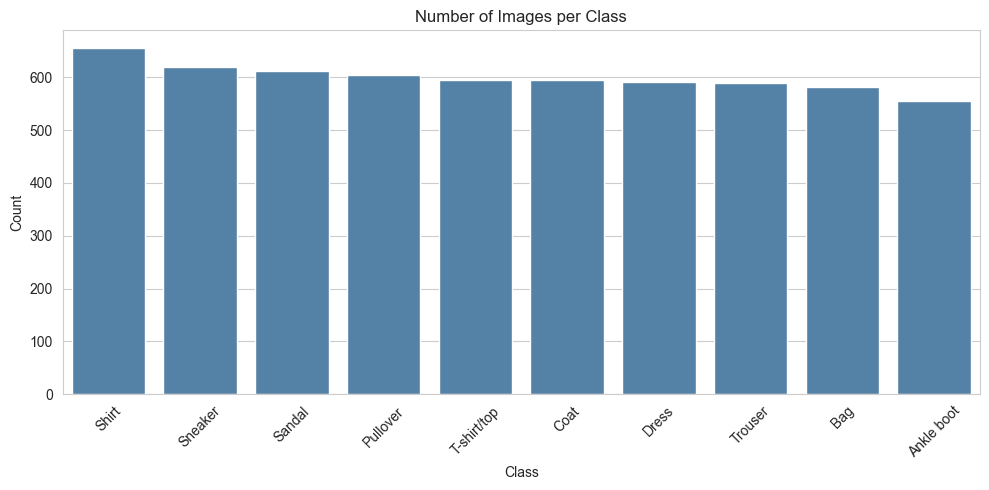

label
Shirt          656
Sneaker        619
Sandal         612
Pullover       604
T-shirt/top    595
Coat           595
Dress          591
Trouser        590
Bag            582
Ankle boot     555
Name: count, dtype: int64


In [31]:
label_counts = df["label"].map(class_names).value_counts()

plt.figure(figsize=(10, 5))
sns.barplot(x=label_counts.index, y=label_counts.values, color="steelblue")
plt.title("Number of Images per Class")
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(label_counts)

## Visualize Sample Images

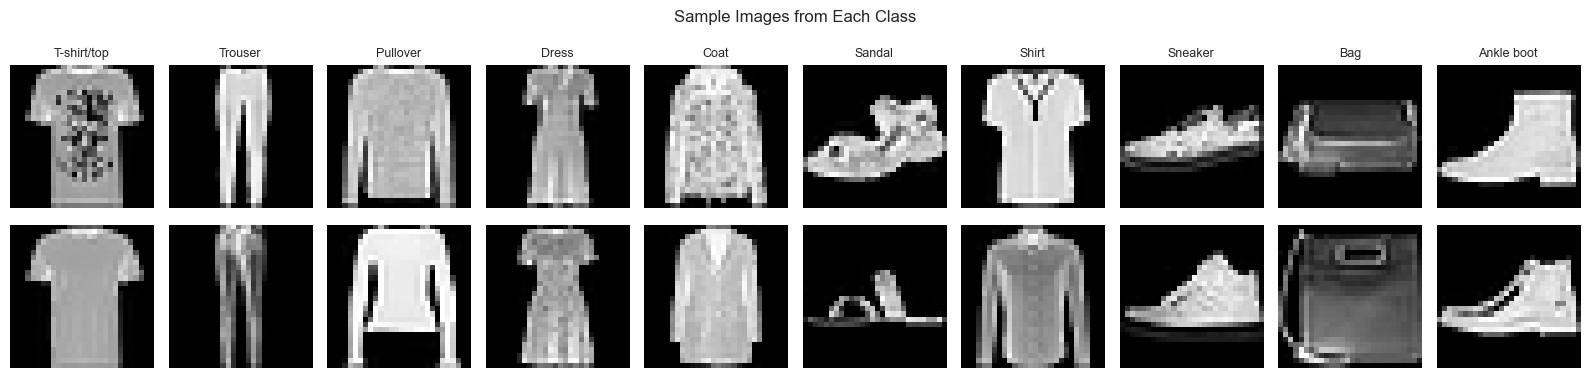

In [32]:
fig, axes = plt.subplots(2, 10, figsize=(16, 4))

for label in range(10):
    samples = df[df["label"] == label].sample(2, random_state=RANDOM_STATE)
    for row in range(2):
        image = samples.iloc[row, 1:].values.reshape(28, 28)
        ax = axes[row, label]
        ax.imshow(image, cmap="gray")
        ax.axis("off")
        if row == 0:
            ax.set_title(class_names[label], fontsize=9)

plt.suptitle("Sample Images from Each Class")
plt.tight_layout()
plt.show()

### Average Image per Class

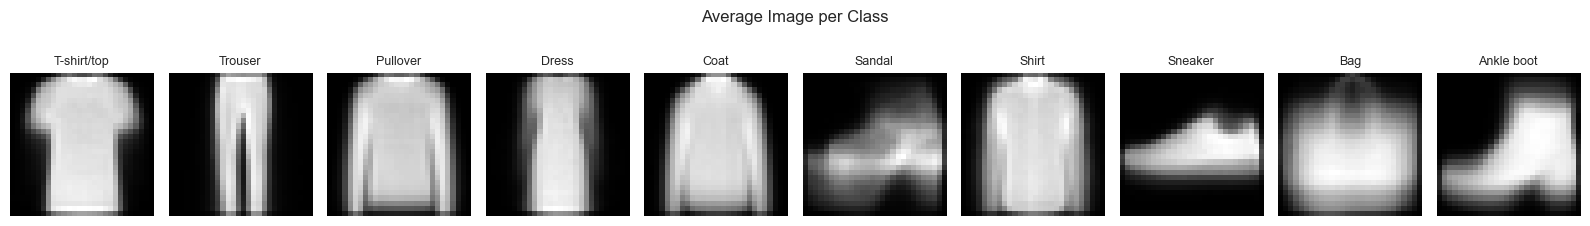

In [33]:
fig, axes = plt.subplots(1, 10, figsize=(16, 2.5))

for label in range(10):
    mean_image = df[df["label"] == label].drop(columns="label").mean().values.reshape(28, 28)
    axes[label].imshow(mean_image, cmap="gray")
    axes[label].set_title(class_names[label], fontsize=9)
    axes[label].axis("off")

plt.suptitle("Average Image per Class")
plt.tight_layout()
plt.show()

Some classes look very similar on average (T-shirt, Pullover, Coat, Shirt).

## Pixel Intensity Distribution

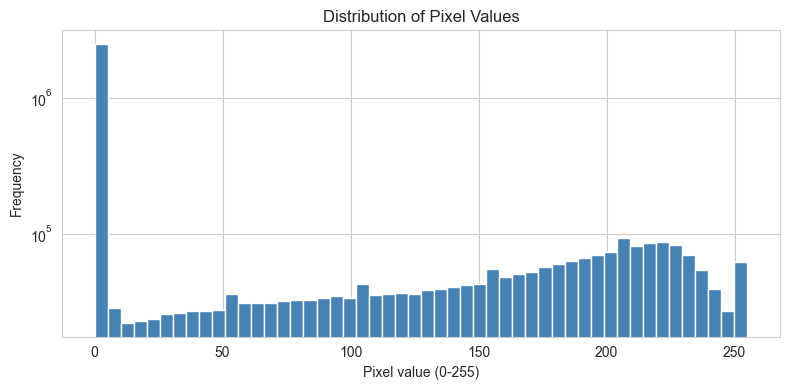

Percentage of zero (background) pixels: 50.0%


In [34]:
all_pixels = df.drop(columns="label").values.flatten()

plt.figure(figsize=(8, 4))
plt.hist(all_pixels, bins=50, color="steelblue")
plt.title("Distribution of Pixel Values")
plt.xlabel("Pixel value (0-255)")
plt.ylabel("Frequency")
plt.yscale("log")  # log scale because most pixels are 0 (background)
plt.tight_layout()
plt.show()

print(f"Percentage of zero (background) pixels: {(all_pixels == 0).mean() * 100:.1f}%")

Most pixels are 0 (black background). Pixel values range from 0 to 255,
so we will scale them to 0–1 before training — neural networks train
much better with small, consistent input values.

## Separate Features and Target

In [35]:
X = df.drop(columns="label").values
y = df["label"].values

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (5999, 784)
y shape: (5999,)


## Train-Test Split

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y, # stratify=y keeps the same class proportions in both train and test sets
)

print("Training set:", X_train.shape, y_train.shape)
print("Test set:    ", X_test.shape, y_test.shape)

Training set: (4799, 784) (4799,)
Test set:     (1200, 784) (1200,)


### Check that the class balance is preserved after splitting

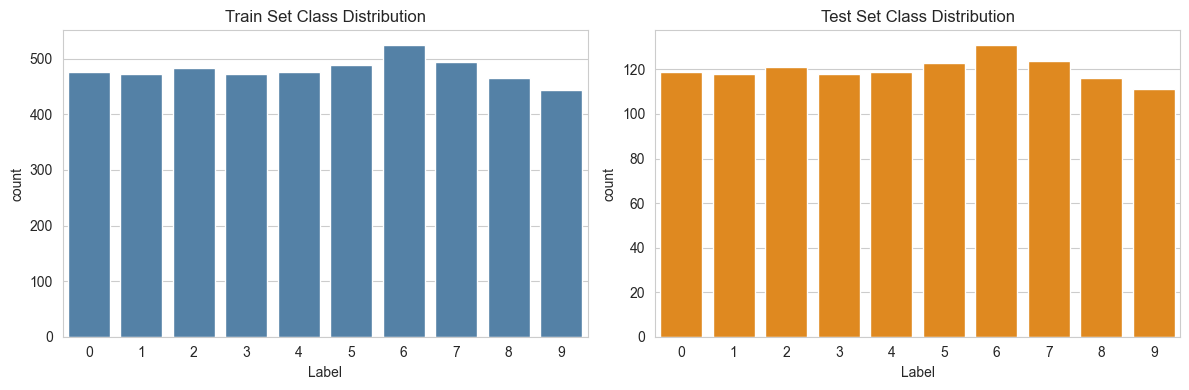

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)

sns.countplot(x=y_train, ax=axes[0], color="steelblue")
axes[0].set_title("Train Set Class Distribution")
axes[0].set_xlabel("Label")

sns.countplot(x=y_test, ax=axes[1], color="darkorange")
axes[1].set_title("Test Set Class Distribution")
axes[1].set_xlabel("Label")

plt.tight_layout()
plt.show()

## Feature Scaling

In [38]:
X_train = X_train.astype("float32") / 255.0 # Divide by 255 so every pixel is between 0 and 1.
X_test = X_test.astype("float32") / 255.0

y_train = y_train.astype("int64")
y_test = y_test.astype("int64")

print("X_train range:", X_train.min(), "to", X_train.max())
print("X_test range: ", X_test.min(), "to", X_test.max())

X_train range: 0.0 to 1.0
X_test range:  0.0 to 1.0


## Final Data Summary

In [39]:
print("X_train:", X_train.shape, X_train.dtype)
print("y_train:", y_train.shape, y_train.dtype)
print("X_test: ", X_test.shape, X_test.dtype)
print("y_test: ", y_test.shape, y_test.dtype)
print("Number of classes:", len(np.unique(y_train)))

X_train: (4799, 784) float32
y_train: (4799,) int64
X_test:  (1200, 784) float32
y_test:  (1200,) int64
Number of classes: 10


---
## Model Training

### Create the Dataset and DataLoaders
A `Dataset` tells PyTorch how to get one sample (image + label).
A `DataLoader` groups samples into small batches (here 32 images at a time).

In [40]:
class FashionMNISTDataset(Dataset):
    def __init__(self, features, labels):
        self.features = torch.tensor(features, dtype=torch.float32)
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.features)

    def __getitem__(self, index):
        return self.features[index], self.labels[index]


train_dataset = FashionMNISTDataset(X_train, y_train)
test_dataset = FashionMNISTDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

features, labels = next(iter(train_loader))
print("Batch features:", features.shape)  # 32 images, 784 pixels each
print("Batch labels:  ", labels.shape)    # 32 labels

Batch features: torch.Size([32, 784])
Batch labels:   torch.Size([32])


### Build the Model
A simple neural network with 3 layers:
- Input: 784 pixels
- Two hidden layers (128 and 64 neurons) with ReLU activation
- Output: 10 numbers, one score per class

In [41]:
class FashionMNISTClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(features.shape[1], 128),
            nn.ReLU(),
            nn.Dropout(0.3), # Randomly turn off 30% of neurons during training

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),  # Randomly turn off 30% of neurons during training

            nn.Linear(64, 10),
        )

    def forward(self, x):
        return self.model(x)


model = FashionMNISTClassifier()
print(model)

FashionMNISTClassifier(
  (model): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=64, out_features=10, bias=True)
  )
)


### Loss Function and Optimizer
- **Loss function** (`CrossEntropyLoss`): measures how wrong the predictions are.
- **Optimizer** (`Adam`): updates the model's weights to reduce the loss.

In [42]:
learning_rate = 0.001
epochs = 20

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

### Training Loop
For every batch: make predictions → compute loss → compute gradients → update weights.
One **epoch** means the model has seen every training image once.

In [43]:
loss_history = []
train_acc_history = []
test_acc_history = []

for epoch in range(epochs):
    model.train()                                 
    total_loss = 0
    correct = 0
    total = 0

    for batch_features, batch_labels in train_loader:
        outputs = model(batch_features)           # Forward pass
        loss = criterion(outputs, batch_labels)   # Calculate loss

        optimizer.zero_grad()                     # Clear old gradients
        loss.backward()                           # Backpropagation
        optimizer.step()                          # Update weights

        total_loss += loss.item()
        correct += (outputs.argmax(dim=1) == batch_labels).sum().item()
        total += len(batch_labels)

    avg_loss = total_loss / len(train_loader)
    train_acc = correct / total

    model.eval()                                 
    test_correct = 0
    test_total = 0

    with torch.no_grad():
        for batch_features, batch_labels in test_loader:
            outputs = model(batch_features)
            test_correct += (outputs.argmax(dim=1) == batch_labels).sum().item()
            test_total += len(batch_labels)

    test_acc = test_correct / test_total

    loss_history.append(avg_loss)
    train_acc_history.append(train_acc)
    test_acc_history.append(test_acc)

    print(f"Epoch {epoch + 1}/{epochs}, Loss: {avg_loss:.4f}, "
          f"Train Acc: {train_acc:.4f}, Test Acc: {test_acc:.4f}")

Epoch 1/20, Loss: 1.2849, Train Acc: 0.5305, Test Acc: 0.6967
Epoch 2/20, Loss: 0.8237, Train Acc: 0.6918, Test Acc: 0.7433
Epoch 3/20, Loss: 0.7026, Train Acc: 0.7424, Test Acc: 0.7767
Epoch 4/20, Loss: 0.6262, Train Acc: 0.7745, Test Acc: 0.8075
Epoch 5/20, Loss: 0.5834, Train Acc: 0.7925, Test Acc: 0.7967
Epoch 6/20, Loss: 0.5398, Train Acc: 0.8048, Test Acc: 0.8033
Epoch 7/20, Loss: 0.5144, Train Acc: 0.8202, Test Acc: 0.8267
Epoch 8/20, Loss: 0.4944, Train Acc: 0.8198, Test Acc: 0.8167
Epoch 9/20, Loss: 0.4703, Train Acc: 0.8254, Test Acc: 0.8317
Epoch 10/20, Loss: 0.4662, Train Acc: 0.8287, Test Acc: 0.8217
Epoch 11/20, Loss: 0.4446, Train Acc: 0.8362, Test Acc: 0.8400
Epoch 12/20, Loss: 0.4362, Train Acc: 0.8425, Test Acc: 0.8375
Epoch 13/20, Loss: 0.4044, Train Acc: 0.8541, Test Acc: 0.8325
Epoch 14/20, Loss: 0.4011, Train Acc: 0.8529, Test Acc: 0.8383
Epoch 15/20, Loss: 0.3866, Train Acc: 0.8556, Test Acc: 0.8483
Epoch 16/20, Loss: 0.3818, Train Acc: 0.8543, Test Acc: 0.8342
E

### Learning Curves

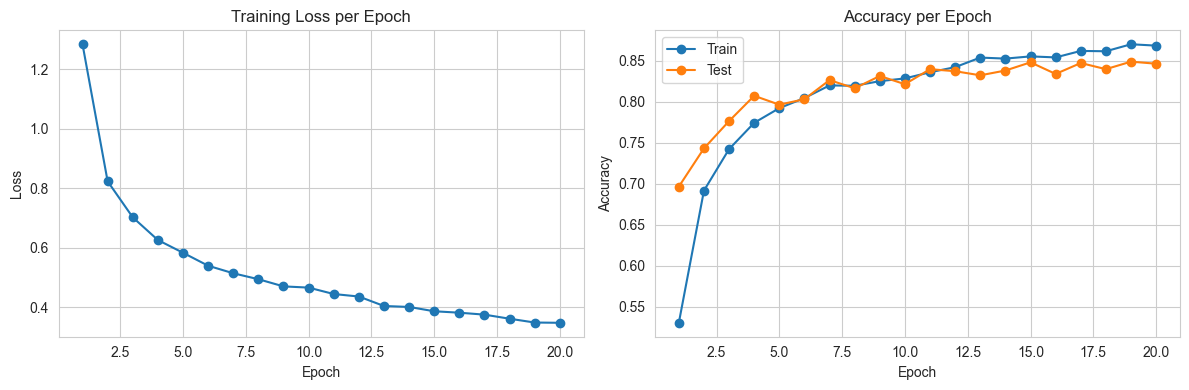

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(range(1, epochs + 1), loss_history, marker="o")
axes[0].set_title("Training Loss per Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")

axes[1].plot(range(1, epochs + 1), train_acc_history, marker="o", label="Train")
axes[1].plot(range(1, epochs + 1), test_acc_history, marker="o", label="Test")
axes[1].set_title("Accuracy per Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

## Evaluate on the Test Set

In [ ]:
model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for batch_features, batch_labels in test_loader:
        outputs = model(batch_features)
        predictions = outputs.argmax(dim=1)   # Class with the highest score

        all_predictions.extend(predictions.numpy())
        all_labels.extend(batch_labels.numpy())

accuracy = accuracy_score(all_labels, all_predictions)
print(f"Test Accuracy: {accuracy:.4f}")

Test Accuracy: 0.8467


### Classification Report

In [46]:
print(classification_report(all_labels, all_predictions, target_names=list(class_names.values())))

              precision    recall  f1-score   support

 T-shirt/top       0.82      0.86      0.84       119
     Trouser       0.97      0.97      0.97       118
    Pullover       0.84      0.71      0.77       121
       Dress       0.84      0.87      0.86       118
        Coat       0.79      0.62      0.69       119
      Sandal       0.94      0.93      0.94       123
       Shirt       0.58      0.76      0.66       131
     Sneaker       0.96      0.87      0.92       124
         Bag       0.95      0.91      0.93       116
  Ankle boot       0.89      0.97      0.93       111

    accuracy                           0.85      1200
   macro avg       0.86      0.85      0.85      1200
weighted avg       0.86      0.85      0.85      1200



### Confusion Matrix

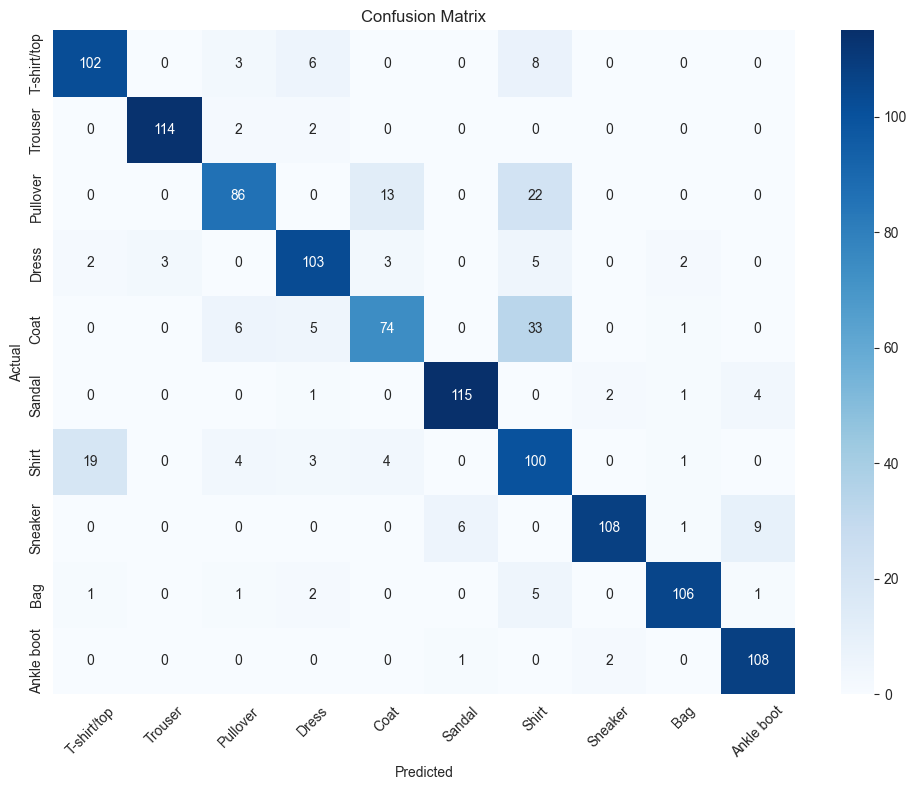

In [47]:
cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names.values(), yticklabels=class_names.values())
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

---
## Save the Model

In [48]:
os.makedirs("../models", exist_ok=True)
torch.save(model.state_dict(), "../models/fashion_model.pt")
print("Model saved!")

Model saved!
